## Web server interface at https://xxxx:7473

#### Update - since the videos were filmed, neo4j requires a longer, more complex password, so the newest password is here:

**Username: neo4j**

**Password: YOUR_PASSWORD**

The above web server allows and interactive GUI which can output graphs visually in addition to table like output.  The nodes in the graphs can be moved around with the mouse to make the graphs more readable.


#### Basics:

```:server connect``` - connect to the server, username is "neo4j", password is "YOUR_PASSWORD"


```:server status``` - shows that username and server you are logged into


```:clear``` - clears off old cells


```show databases``` - note that community edition only has 1 application database that we can use neo4j, we cannot create now use other databases, we have to wipe out neo4j database for each new graph


## In the Neo4j GUI, run the following query with graph output and rearrange the nodes with your mouse if necessary:

```match (n) return n```

In [1]:
import neo4j

import pandas as pd

import re

from IPython.display import display

In [2]:
driver = neo4j.GraphDatabase.driver(uri="neo4j://neo4j:7687", auth=("neo4j","YOUR_PASSWORD"))

In [3]:
session = driver.session(database="neo4j")

In [4]:
def my_neo4j_wipe_out_database():
    "wipe out database by deleting all nodes and relationships"
    
    query = "match (node)-[relationship]->() delete node, relationship"
    session.run(query)
    
    query = "match (node) delete node"
    session.run(query)

In [5]:
def my_neo4j_run_query_pandas(query, **kwargs):
    "run a query and return the results in a pandas dataframe"
    
    result = session.run(query, **kwargs)
    
    df = pd.DataFrame([r.values() for r in result], columns=result.keys())
    
    return df

In [6]:
def my_neo4j_nodes_relationships():
    "print all the nodes and relationships"
   
    print("-------------------------")
    print("  Nodes:")
    print("-------------------------")
    
    query = """
        match (n) 
        return n.name as node_name, labels(n) as labels
        order by n.name
    """
    
    df = my_neo4j_run_query_pandas(query)
    
    number_nodes = df.shape[0]
    
    display(df)
    
    print("-------------------------")
    print("  Relationships:")
    print("-------------------------")
    
    query = """
        match (n1)-[r]->(n2) 
        return n1.name as node_name_1, labels(n1) as node_1_labels, 
            type(r) as relationship_type, n2.name as node_name_2, labels(n2) as node_2_labels
        order by node_name_1, node_name_2
    """
    
    df = my_neo4j_run_query_pandas(query)
    
    number_relationships = df.shape[0]
    
    display(df)
    
    density = (2 * number_relationships) / (number_nodes * (number_nodes - 1))
    
    print("-------------------------")
    print("  Density:", f'{density:.1f}')
    print("-------------------------")
    

In [7]:
# Function to sanitize Neo4j variable names
def sanitize_variable_name(name):
    name = name.lower()
    name = re.sub(r'[^a-z0-9_]', '_', name)  # Replace non-alphanumeric characters with _
    name = re.sub(r'_+', '_', name)          # Collapse multiple underscores
    name = name.strip('_')                   # Remove leading/trailing underscores
    if not name or not name[0].isalpha():    # Ensure it starts with a letter
        name = 'n_' + name
    return name

# Load data directly from GitHub
url = "https://raw.githubusercontent.com/rfordatascience/tidytuesday/main/data/2023/2023-08-22/population.csv"
df = pd.read_csv(url)

In [8]:
# Filter for year 2010 and refugee flows > 5000
# Adjust as necessary

df = df[(df["year"] == 2010) & (df["refugees"] > 5000)][["coo_name", "coa_name", "refugees"]].dropna()
df["refugees"] = df["refugees"].astype(int)

In [9]:
# Wipe Neo4j database
my_neo4j_wipe_out_database()

# Build Cypher query
query = "CREATE\n"
country_nodes = set()

for i, row in df.iterrows():
    origin = row["coo_name"].replace("'", "\\'")
    asylum = row["coa_name"].replace("'", "\\'")
    count = row["refugees"]

    origin_var = sanitize_variable_name(origin)
    asylum_var = sanitize_variable_name(asylum)

    if origin not in country_nodes:
        query += f"  ({origin_var}:Country {{name: '{origin}'}}),\n"
        country_nodes.add(origin)

    if asylum not in country_nodes:
        query += f"  ({asylum_var}:Country {{name: '{asylum}'}}),\n"
        country_nodes.add(asylum)

    query += f"  ({origin_var})-[:REFUGEES {{count: {count}}}]->({asylum_var}),\n"

# Clean trailing comma
query = query.rstrip(",\n")

# Run the query in Neo4j
session.run(query)

In [10]:
my_neo4j_nodes_relationships()

-------------------------
  Nodes:
-------------------------


,node_name,labels
0,Afghanistan,[Country]
1,Albania,[Country]
2,Algeria,[Country]
3,Angola,[Country]
4,Armenia,[Country]
...,...,...
90,Viet Nam,[Country]
91,Western Sahara,[Country]
92,Yemen,[Country]
93,Zambia,[Country]


-------------------------
  Relationships:
-------------------------


,node_name_1,node_1_labels,relationship_type,node_name_2,node_2_labels
0,Afghanistan,[Country],REFUGEES,Australia,[Country]
1,Afghanistan,[Country],REFUGEES,Austria,[Country]
2,Afghanistan,[Country],REFUGEES,Germany,[Country]
3,Afghanistan,[Country],REFUGEES,India,[Country]
4,Afghanistan,[Country],REFUGEES,Iran (Islamic Rep. of),[Country]
...,...,...,...,...,...
158,Viet Nam,[Country],REFUGEES,France,[Country]
159,Viet Nam,[Country],REFUGEES,Germany,[Country]
160,Western Sahara,[Country],REFUGEES,Algeria,[Country]
161,Western Sahara,[Country],REFUGEES,Mauritania,[Country]


-------------------------
  Density: 0.0
-------------------------


## Running Degree Centrality on one graph (Graph1), with high degree centrality showing countries with the most creation of refugees / grant asylum

In [11]:
#notes
#outgoing = leaving country of origin (coo_name) 
#incoming = arriving at country of asylum (coa_name) 
#Ex coo:Syria ---> coa:Germany

In [12]:
#Drop previous refugeeGraph if it exists
query = "CALL gds.graph.drop('refugeeGraph', false) yield graphName"
session.run(query)

#Re- Display graph as a directed graph
query = """

CALL gds.graph.project(
    'refugeeGraph',
    'Country',
    'REFUGEES'
)
"""
session.run(query)

In [13]:
#Get incoming and outgoing


#outgoing of coo
query = """

CALL gds.degree.stream('refugeeGraph', {orientation:'NATURAL'})
YIELD nodeId, score
RETURN gds.util.asNode(nodeId).name AS country, score AS outgoing_degree
ORDER BY outgoing_degree DESC

"""
outgoing_df = my_neo4j_run_query_pandas(query)


#incoming to coa

query = """

CALL gds.degree.stream('refugeeGraph', {orientation:'REVERSE'})
YIELD nodeId, score
RETURN gds.util.asNode(nodeId).name AS country, score AS incoming_degree
ORDER BY incoming_degree DESC

"""
incoming_df = my_neo4j_run_query_pandas(query)





In [14]:
#save incoming results to csv
incoming_df = incoming_df.head(10)
incoming_df.to_csv("2010DegreeCentrality_incoming.csv", index=False)


In [15]:
#save outgoing results to csv
outgoing_df = outgoing_df.head(10)
outgoing_df.to_csv("2010DegreeCentrality_outgoing.csv", index=False)

In [16]:
##Observation - the country with the highest degree centrality (aka or highest connection count) in the refugee network is Syrian Arab Republic

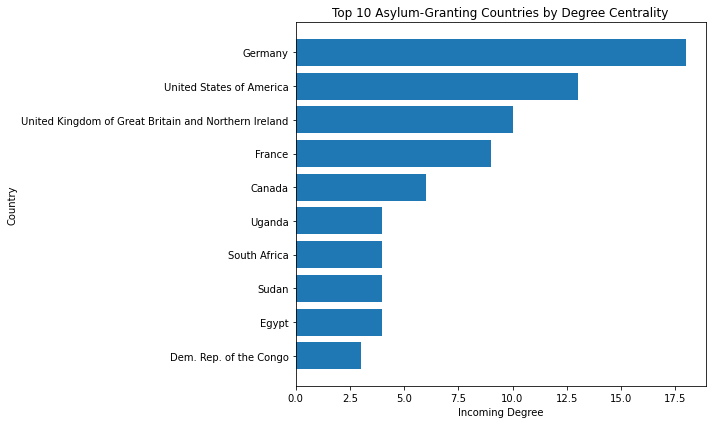

In [17]:
#bar chart for top 10 Asylum Granting Countries 
import matplotlib.pyplot as plt

# Optional: sort values for better visual
incoming_df = incoming_df.sort_values(by="incoming_degree", ascending=True)

# Plot
plt.figure(figsize=(10, 6))
plt.barh(incoming_df["country"], incoming_df["incoming_degree"]) 
plt.title("Top 10 Asylum-Granting Countries by Degree Centrality") 
plt.xlabel("Incoming Degree") 
plt.ylabel("Country")
plt.tight_layout()
plt.show()


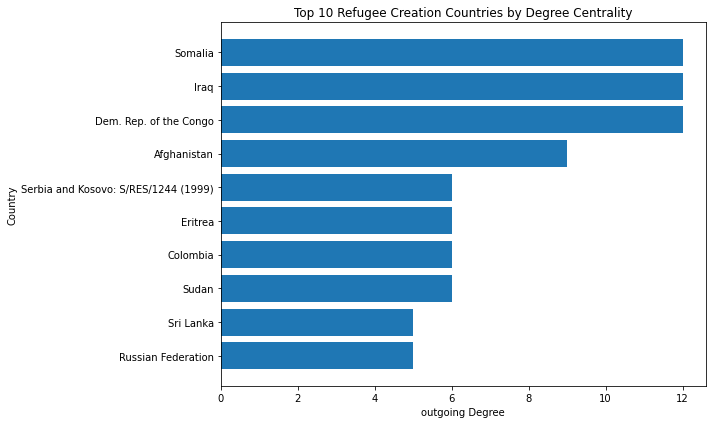

In [18]:
#bar chart for Top 10 Refugee Creation Countries (outgoing) 
import matplotlib.pyplot as plt

# Optional: sort values for better visual
outgoing_df = outgoing_df.sort_values(by="outgoing_degree", ascending=True)

# Plot
plt.figure(figsize=(10, 6))
plt.barh(outgoing_df["country"], outgoing_df["outgoing_degree"])
plt.title("Top 10 Refugee Creation Countries by Degree Centrality")
plt.xlabel("outgoing Degree")
plt.ylabel("Country")
plt.tight_layout()
plt.show()
